# 02 · Learning from experience: Monte Carlo, TD, SARSA and Q-learning

In notebook 00 we solved an MDP with **dynamic programming** (value / policy iteration). That only works
if someone hands us the transition probabilities $P(s' \mid s, a)$ and the reward function. Real problems
almost never come with that manual: a robot does not know the physics of its gripper in closed form, and
an LLM certainly has no table of "probability that the user will be happy after this token".

This notebook is about **model-free** reinforcement learning: learning values and policies purely from
*sampled experience* $(s, a, r, s')$. Every algorithm here is tabular (one number per state or
state-action pair), so you can literally print the whole "brain" of the agent. Notebook 03 replaces the
table with a neural network (DQN), and from notebook 04 on we move to policy-gradient methods used for LLMs
- but the **TD error** you meet here is the same quantity that powers the PPO critic and GAE used in RLHF.

```mermaid
flowchart LR
    N00[00 Foundations<br/>MDP, Bellman, DP] --> N01[01 Bandits<br/>exploration]
    N01 --> N02[02 Tabular TD<br/>MC, TD, SARSA, Q-learning]:::here
    N02 --> N03[03 DQN<br/>neural Q-functions]
    N02 --> N04[04 Policy gradient]
    N04 --> N05[05 Actor-critic & GAE<br/>uses the TD error!]
    N05 --> N06[06 PPO] --> N07[07 RLHF]
    classDef here fill:#2563eb,color:#fff,stroke:#1e3a8a,stroke-width:3px
```

**What you will learn**

| Section | Algorithm | Question it answers |
|---|---|---|
| 1 | Monte Carlo (MC) prediction | "How good is a state?" - by averaging complete returns |
| 2 | TD(0) prediction | Same question, but learning *after every step* by bootstrapping |
| 3 | n-step TD | The dial between MC and TD |
| 4 | SARSA | Learn to *act* (control), on-policy |
| 5 | Q-learning | Learn to act optimally while behaving exploratorily (off-policy) |
| 6 | Double Q-learning | Fix the *maximization bias* of Q-learning (sets up Double DQN) |
| 7 | Connections to LLMs | TD errors in PPO critics, Q-functions over tokens (ILQL, "LLM logits are Q-values") |

## 0 · Setup and notation recap

| Symbol | Meaning |
|---|---|
| $s_t, a_t, r_{t+1}$ | state, action, and the reward received *after* taking $a_t$ |
| $\gamma \in [0,1]$ | discount factor |
| $G_t = r_{t+1} + \gamma r_{t+2} + \gamma^2 r_{t+3} + \dots$ | the **return**: total discounted future reward |
| $V^\pi(s) = \mathbb{E}_\pi[G_t \mid s_t = s]$ | state value under policy $\pi$ |
| $Q^\pi(s,a) = \mathbb{E}_\pi[G_t \mid s_t = s, a_t = a]$ | action value |
| $\alpha$ | learning rate / step size |

The single most useful identity in this notebook is the **recursive definition of the return**:

$$G_t = r_{t+1} + \gamma\, G_{t+1}.$$

MC methods use the left-hand side (wait for the true $G_t$). TD methods use the right-hand side and
replace the unknown $G_{t+1}$ with the current *estimate* $V(s_{t+1})$. That replacement is called
**bootstrapping** - "pulling yourself up by your own bootstraps", i.e. learning a guess from a guess.

In [1]:
# Setup: make the shared `rlkit` helpers (plots, GIFs, toy envs, tiny models) importable.
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))
%matplotlib inline

In [2]:
import math
import random
import statistics
import time

import matplotlib.pyplot as plt
import numpy as np

from rlkit.viz import COLORS, Animator, asset_path, draw_arrow, draw_box, save_figure, setup_style, show_frame, smooth

setup_style()
NOTEBOOK_START = time.perf_counter()
print("ready")

ready


### A picture first: three ways to "back up" a value

A **backup diagram** shows *which future information* is used to update the value of the state at the top.

* **Dynamic programming** looks one step ahead but over *all* possible next states (needs the model).
* **Monte Carlo** follows *one* sampled path all the way to the end of the episode.
* **TD(0)** follows *one* sampled step and then trusts the current estimate $V(s')$.

The figure below is generated with matplotlib (and saved to `assets/rl/course/02_backup_diagrams.png`).

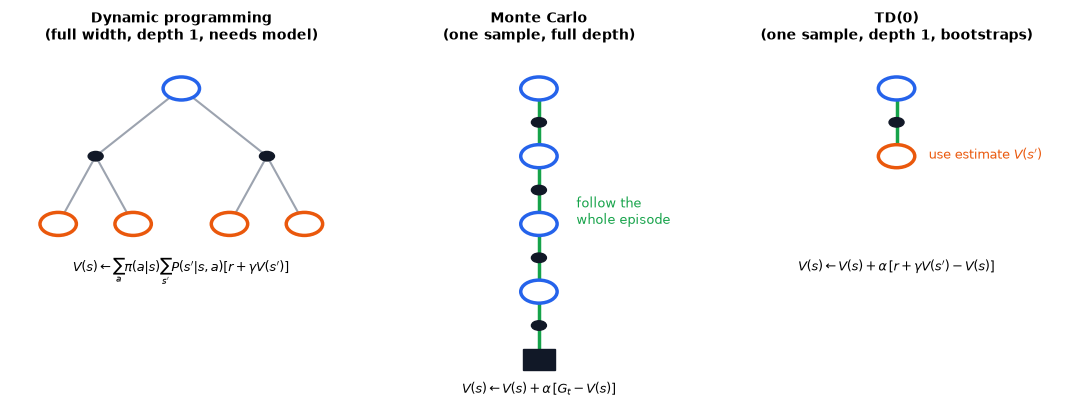

In [3]:
def draw_backup_diagrams():
    """Draw DP / MC / TD backup diagrams side by side (open circle = state, dot = action)."""
    fig, axes = plt.subplots(1, 3, figsize=(11, 4.2))
    titles = ["Dynamic programming\n(full width, depth 1, needs model)",
              "Monte Carlo\n(one sample, full depth)",
              "TD(0)\n(one sample, depth 1, bootstraps)"]
    for ax, title in zip(axes, titles):
        ax.set_xlim(-1.6, 1.6); ax.set_ylim(-4.6, 0.6); ax.axis("off"); ax.set_title(title, fontsize=10)

    def state(ax, x, y, color=COLORS["policy"], terminal=False):
        if terminal:
            ax.add_patch(plt.Rectangle((x - 0.15, y - 0.15), 0.3, 0.3, color=COLORS["ink"]))
        else:
            ax.add_patch(plt.Circle((x, y), 0.17, fc="white", ec=color, lw=2.5))

    def action(ax, x, y):
        ax.add_patch(plt.Circle((x, y), 0.07, color=COLORS["ink"]))

    def line(ax, a, b, color="#9ca3af", lw=1.5):
        ax.plot([a[0], b[0]], [a[1], b[1]], color=color, lw=lw, zorder=0)

    # DP: root -> all actions -> all next states
    ax = axes[0]
    state(ax, 0, 0)
    for ax_x in (-0.8, 0.8):
        line(ax, (0, 0), (ax_x, -1)); action(ax, ax_x, -1)
        for dx in (-0.35, 0.35):
            line(ax, (ax_x, -1), (ax_x + dx, -2)); state(ax, ax_x + dx, -2, COLORS["value"])
    ax.text(0, -2.7, r"$V(s) \leftarrow \sum_a \pi(a|s)\sum_{s'} P(s'|s,a)[r + \gamma V(s')]$",
            ha="center", fontsize=9)

    # MC: a single chain to a terminal state
    ax = axes[1]
    y = 0
    for k in range(4):
        state(ax, 0, y); line(ax, (0, y), (0, y - 0.5), COLORS["reward"], 2.5); action(ax, 0, y - 0.5)
        line(ax, (0, y - 0.5), (0, y - 1), COLORS["reward"], 2.5); y -= 1
    state(ax, 0, y, terminal=True)
    ax.text(0.35, -2, "follow the\nwhole episode", fontsize=9, color=COLORS["reward"])
    ax.text(0, -4.5, r"$V(s) \leftarrow V(s) + \alpha\,[G_t - V(s)]$", ha="center", fontsize=9)

    # TD(0): one step then the estimate
    ax = axes[2]
    state(ax, 0, 0); line(ax, (0, 0), (0, -0.5), COLORS["reward"], 2.5); action(ax, 0, -0.5)
    line(ax, (0, -0.5), (0, -1), COLORS["reward"], 2.5); state(ax, 0, -1, COLORS["value"])
    ax.text(0.3, -1.05, r"use estimate $V(s')$", fontsize=9, color=COLORS["value"])
    ax.text(0, -2.7, r"$V(s) \leftarrow V(s) + \alpha\,[r + \gamma V(s') - V(s)]$", ha="center", fontsize=9)
    plt.tight_layout()
    save_figure(fig, "02_backup_diagrams.png")
    plt.show()


draw_backup_diagrams()

## 1 · The test-bed for prediction: the 5-state Random Walk

To compare *prediction* algorithms (estimating $V^\pi$ for a fixed policy) we use the classic Random Walk
from Sutton & Barto (Example 6.2):

```
 [0] ← A ↔ B ↔ C ↔ D ↔ E → [+1]
              start
```

* every episode starts in the middle state **C**;
* at each step the agent moves left or right with probability 1/2 (the policy is fixed - we only *evaluate* it);
* reaching the right end gives reward **+1**, the left end gives **0**, every other reward is 0; $\gamma = 1$.

Because the dynamics are so simple, we know the **true values**: $V(s)$ is the probability of finishing on
the right, i.e. $V(A..E) = 1/6, 2/6, 3/6, 4/6, 5/6$. That lets us measure exactly how wrong each
algorithm's estimate is (root-mean-square error, RMS).

In [4]:
class RandomWalk:
    """The 5-state random walk (Sutton & Barto, Example 6.2), written from scratch.

    States are integers 1..n (A..E for n=5); 0 and n+1 are the terminal states.
    Reaching n+1 pays `right_reward`, reaching 0 pays `left_reward`.
    """

    def __init__(self, n_states=5, left_reward=0.0, right_reward=1.0):
        self.n = n_states
        self.left_reward = left_reward
        self.right_reward = right_reward

    def episode(self, rng):
        """Run the fixed 50/50 policy once. Returns a list of (state, reward, next_state, done)."""
        s = (self.n + 1) // 2  # start in the middle
        transitions = []
        while True:
            s2 = s + (1 if rng.random() < 0.5 else -1)
            if s2 == 0:
                transitions.append((s, self.left_reward, s2, True)); return transitions
            if s2 == self.n + 1:
                transitions.append((s, self.right_reward, s2, True)); return transitions
            transitions.append((s, 0.0, s2, False))
            s = s2


walk = RandomWalk()
TRUE_V = [i / 6 for i in range(1, 6)]
rng = random.Random(0)
for _ in range(3):
    ep = walk.episode(rng)
    print(" -> ".join("ABCDE"[s - 1] for s, *_ in ep), "-> end, reward", ep[-1][1])

C -> B -> A -> B -> C -> B -> C -> B -> C -> D -> C -> B -> A -> B -> A -> end, reward 0.0
C -> D -> C -> B -> A -> end, reward 0.0
C -> D -> C -> B -> A -> B -> C -> D -> C -> B -> A -> B -> A -> B -> A -> end, reward 0.0


## 2 · Monte Carlo prediction

### Intuition
You want to know how long your commute takes. The Monte Carlo way: drive to work many times, write down
the *total* time of each trip, and average. No theory of traffic needed - just complete experiences.

### Math, step by step
By definition $V^\pi(s) = \mathbb{E}_\pi[G_t \mid s_t = s]$. The law of large numbers says the sample mean
of returns observed from $s$ converges to that expectation:

$$V(s) \approx \frac{1}{N(s)} \sum_{i=1}^{N(s)} G^{(i)}(s).$$

Computing a running mean incrementally, after seeing the $N$-th return $G$:

$$\bar G_N = \bar G_{N-1} + \frac{1}{N}\big(G - \bar G_{N-1}\big).$$

Replace $1/N$ by a constant step size $\alpha$ (so that recent episodes weigh more - useful when the
policy changes) and you get **constant-$\alpha$ MC**:

$$\boxed{V(s_t) \leftarrow V(s_t) + \alpha\,\big[\,G_t - V(s_t)\,\big]}$$

Read it as *"move the estimate a little bit towards the target"*. The target $G_t$ is an **unbiased** sample
of $V^\pi(s_t)$, but it can have **high variance** because it sums many random rewards.

### Algorithm steps (every-visit, constant-α MC)

1. **Initialise** $V(s)$ arbitrarily (here 0.5) for every non-terminal state.
2. **Generate an episode** $s_0, r_1, s_1, r_2, \dots, s_T$ by following $\pi$ until termination.
   *Why:* MC needs the complete return, so it cannot learn mid-episode.
3. **Compute returns backwards**: $G \leftarrow 0$; for $t = T-1, \dots, 0$: $G \leftarrow r_{t+1} + \gamma G$.
   *Why:* going backwards turns the sum into one multiply-add per step (the recursion $G_t = r_{t+1} + \gamma G_{t+1}$).
4. **Update** each visited state: $V(s_t) \leftarrow V(s_t) + \alpha [G - V(s_t)]$.
5. **Repeat** from step 2.

In [5]:
def mc_prediction(env, episodes, alpha, gamma=1.0, seed=0, init=0.5, history=False):
    """Constant-alpha every-visit Monte Carlo prediction. Returns V (and optionally V after every episode)."""
    rng = random.Random(seed)
    V = [0.0] + [init] * env.n + [0.0]          # index 0 and n+1 are terminal (value 0)
    hist = [V[1:-1].copy()]
    for _ in range(episodes):
        ep = env.episode(rng)                    # step 2: one complete episode
        G = 0.0
        for s, r, _, _ in reversed(ep):          # step 3: returns, computed backwards
            G = r + gamma * G
            V[s] += alpha * (G - V[s])           # step 4: nudge towards the observed return
        hist.append(V[1:-1].copy())
    return (V, hist) if history else V


V_mc = mc_prediction(walk, episodes=2000, alpha=0.01)
print("MC estimate:", [round(v, 3) for v in V_mc[1:-1]])
print("true values:", [round(v, 3) for v in TRUE_V])

MC estimate: [0.111, 0.257, 0.452, 0.658, 0.827]
true values: [0.167, 0.333, 0.5, 0.667, 0.833]


## 3 · Temporal-Difference learning: TD(0)

### Intuition
Back to the commute. You leave the office; after 10 minutes you hit a traffic jam on the highway. You
*already* know the trip will be long - you do not need to wait until you get home to revise your estimate.
TD learning updates "how long from the office" using *"10 minutes so far + my current estimate of how long
from the highway"*. It learns from **every step**, before the outcome is known.

### Math, step by step
Start from the Bellman expectation equation for $V^\pi$ (notebook 00):

$$V^\pi(s) = \mathbb{E}_\pi\big[r_{t+1} + \gamma V^\pi(s_{t+1}) \mid s_t = s\big].$$

1. We cannot compute the expectation (no model), so take **one sample**: $r_{t+1} + \gamma V^\pi(s_{t+1})$.
2. We do not know $V^\pi(s_{t+1})$ either, so use our **current estimate** $V(s_{t+1})$ (bootstrapping).
3. This gives the **TD target** $\;y_t = r_{t+1} + \gamma V(s_{t+1})$, used exactly like $G_t$ in MC:

$$\boxed{V(s_t) \leftarrow V(s_t) + \alpha\,\underbrace{\big[r_{t+1} + \gamma V(s_{t+1}) - V(s_t)\big]}_{\delta_t\ =\ \text{TD error}}}$$

The **TD error** $\delta_t$ measures *surprise*: positive if things went better than expected, negative if
worse. (Neuroscience fun fact: the firing of dopamine neurons closely tracks a TD error - Schultz, Dayan &
Montague, 1997.)

**Bias vs variance.** The TD target depends on one random reward and one random next state, so it has much
lower variance than $G_t$. But it is **biased** while $V$ is still wrong. In practice the variance reduction
usually wins: TD typically learns faster than MC - we will measure this below. Remember this trade-off;
GAE in notebook 05 is literally a knob between the two.

| | target | bias | variance | can learn online / mid-episode | needs episode to end |
|---|---|---|---|---|---|
| MC | $G_t$ | none | high | no | yes |
| TD(0) | $r + \gamma V(s')$ | yes (from $V$) | low | yes | no |

### Algorithm steps (TD(0) prediction)

1. **Initialise** $V(s)$ (0.5 here); terminal states have $V = 0$ forever.
2. **Start** an episode in $s$.
3. **Act** with $\pi$, observe $r$ and $s'$.
4. **Compute** the TD error $\delta = r + \gamma V(s') - V(s)$ (use $V(s')=0$ if $s'$ is terminal).
   *Why terminal = 0:* there is no future after the end, so nothing to bootstrap from.
5. **Update** $V(s) \leftarrow V(s) + \alpha\,\delta$, set $s \leftarrow s'$, and go to step 3 until the episode ends.

In [6]:
def td0_prediction(env, episodes, alpha, gamma=1.0, seed=0, init=0.5, history=False):
    """TD(0) prediction: update after every single transition using the bootstrapped target."""
    rng = random.Random(seed)
    V = [0.0] + [init] * env.n + [0.0]
    hist = [V[1:-1].copy()]
    for _ in range(episodes):
        for s, r, s2, done in env.episode(rng):  # step 3: one transition at a time
            target = r + (0.0 if done else gamma * V[s2])   # step 4: bootstrapped TD target
            V[s] += alpha * (target - V[s])                 # step 5: move towards it
        hist.append(V[1:-1].copy())
    return (V, hist) if history else V


V_td = td0_prediction(walk, episodes=2000, alpha=0.01)
print("TD estimate:", [round(v, 3) for v in V_td[1:-1]])
print("true values:", [round(v, 3) for v in TRUE_V])

TD estimate: [0.17, 0.328, 0.492, 0.67, 0.828]
true values: [0.167, 0.333, 0.5, 0.667, 0.833]


### Animation: watching MC and TD estimates converge

Both learners see **the same 60 episodes** (same random seed) with the same step size $\alpha = 0.1$. Bars are
the current estimates, the dashed line is the truth. Watch how:

* TD values change **smoothly** and even states never visited near the end get sensible values early;
* MC values **jump** - each update uses one whole noisy return, so a single lucky/unlucky episode moves them a lot;
* the right panel tracks the RMS error of each method episode by episode.


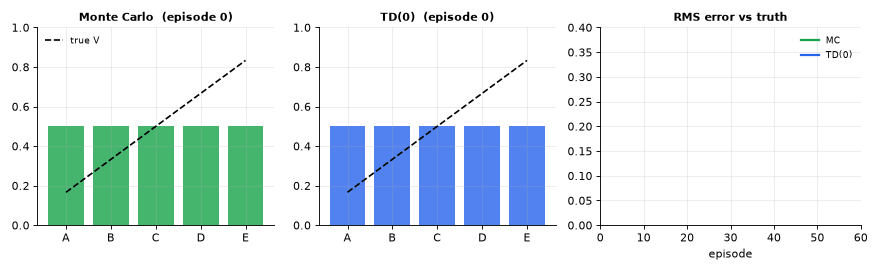

PosixPath('/Users/naveenkumarbasaanitha/Music/HaloDiffusionLLM/assets/rl/course/02_mc_vs_td_random_walk.gif')

In [7]:
def rms(values, truth=TRUE_V):
    return math.sqrt(sum((v - t) ** 2 for v, t in zip(values, truth)) / len(truth))


N_ANIM = 60
_, mc_hist = mc_prediction(walk, N_ANIM, alpha=0.1, seed=3, history=True)
_, td_hist = td0_prediction(walk, N_ANIM, alpha=0.1, seed=3, history=True)
mc_err = [rms(v) for v in mc_hist]
td_err = [rms(v) for v in td_hist]


def draw_walk(fig, i):
    fig.clf()
    gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.1])
    for k, (hist, name, color) in enumerate([(mc_hist, "Monte Carlo", COLORS["reward"]),
                                             (td_hist, "TD(0)", COLORS["policy"])]):
        ax = fig.add_subplot(gs[0, k])
        ax.bar(range(5), hist[i], color=color, alpha=0.8)
        ax.plot(range(5), TRUE_V, "k--", lw=1.5, label="true V")
        ax.set_xticks(range(5)); ax.set_xticklabels(list("ABCDE"))
        ax.set_ylim(0, 1); ax.set_title(f"{name}  (episode {i})", fontsize=10)
        if k == 0:
            ax.legend(loc="upper left", fontsize=8)
    ax = fig.add_subplot(gs[0, 2])
    ax.plot(mc_err[: i + 1], color=COLORS["reward"], lw=2, label="MC")
    ax.plot(td_err[: i + 1], color=COLORS["policy"], lw=2, label="TD(0)")
    ax.set_xlim(0, N_ANIM); ax.set_ylim(0, 0.4)
    ax.set_title("RMS error vs truth", fontsize=10); ax.set_xlabel("episode"); ax.legend(fontsize=8)
    fig.tight_layout()


Animator(draw_walk, n_frames=N_ANIM + 1, figsize=(11, 3.4), fps=6).save("02_mc_vs_td_random_walk.gif")

### Experiment: MC vs TD averaged over 100 runs

One run is anecdotal. Below we repeat the experiment 100 times for several step sizes and plot the average
RMS error over the first 100 episodes (this reproduces the shape of Sutton & Barto's Figure 6.2).

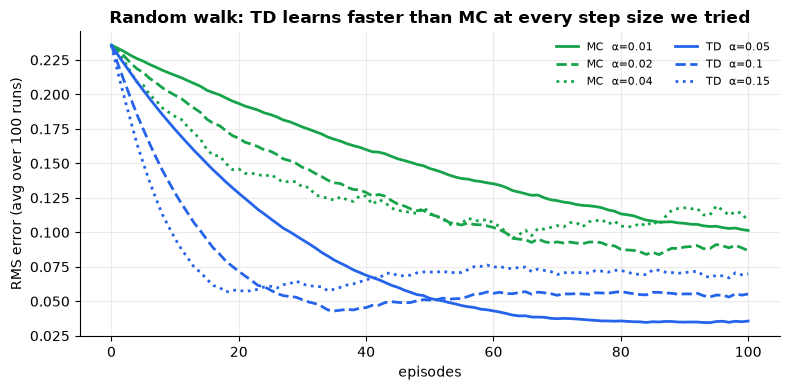

final RMS after 100 episodes - best MC: 0.087, best TD: 0.036  (0.6s)


In [8]:
def learning_curve(algo, alpha, episodes=100, runs=100):
    """Average RMS error after each episode across `runs` independent seeds."""
    total = [0.0] * (episodes + 1)
    for run in range(runs):
        _, hist = algo(walk, episodes, alpha=alpha, seed=run, history=True)
        for k, v in enumerate(hist):
            total[k] += rms(v) / runs
    return total


t0 = time.perf_counter()
fig, ax = plt.subplots(figsize=(8, 4))
curves = {}
for alpha, ls in [(0.01, "-"), (0.02, "--"), (0.04, ":")]:
    curves[f"MC a={alpha}"] = learning_curve(mc_prediction, alpha)
    ax.plot(curves[f"MC a={alpha}"], color=COLORS["reward"], ls=ls, lw=2, label=f"MC  α={alpha}")
for alpha, ls in [(0.05, "-"), (0.1, "--"), (0.15, ":")]:
    curves[f"TD a={alpha}"] = learning_curve(td0_prediction, alpha)
    ax.plot(curves[f"TD a={alpha}"], color=COLORS["policy"], ls=ls, lw=2, label=f"TD  α={alpha}")
ax.set_xlabel("episodes"); ax.set_ylabel("RMS error (avg over 100 runs)")
ax.set_title("Random walk: TD learns faster than MC at every step size we tried")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); save_figure(fig, "02_mc_vs_td_rms.png"); plt.show()

best_mc = min(c[-1] for k, c in curves.items() if k.startswith("MC"))
best_td = min(c[-1] for k, c in curves.items() if k.startswith("TD"))
print(f"final RMS after 100 episodes - best MC: {best_mc:.3f}, best TD: {best_td:.3f}  ({time.perf_counter()-t0:.1f}s)")
assert best_td < best_mc, "TD(0) should beat MC on the random walk"

## 4 · n-step TD: the dial between TD and MC

### Intuition
TD(0) looks 1 step ahead before trusting its estimate; MC looks all the way to the end. Why not look
$n$ steps ahead? **n-step TD** uses $n$ real rewards and then bootstraps.

### Math
The **n-step return** is

$$G_{t:t+n} = r_{t+1} + \gamma r_{t+2} + \dots + \gamma^{n-1} r_{t+n} + \gamma^n V(s_{t+n}),$$

(if the episode ends before $t+n$, it is just the ordinary return). The update is again
$V(s_t) \leftarrow V(s_t) + \alpha[G_{t:t+n} - V(s_t)]$. $n=1$ gives TD(0); $n=\infty$ gives MC.

Each extra real reward reduces bias (less reliance on $V$) and adds variance (more random terms). Usually an
intermediate $n$ is best. Averaging *all* n-step returns with weights $(1-\lambda)\lambda^{n-1}$ gives the
**λ-return**, TD(λ) - and the same idea applied to advantages is **GAE(λ)**, the advantage estimator inside
PPO for RLHF (notebook 05).

### Algorithm steps (n-step TD prediction)

1. Keep a buffer of the last $n+1$ states and rewards of the current episode.
2. At each time step $t$, once you have observed $r_{\tau+1..\tau+n}$ for the state visited at time $\tau = t - n + 1$,
   compute $G_{\tau:\tau+n}$ and update $V(s_\tau)$.
3. When the episode terminates at time $T$, flush the remaining states with truncated returns (no bootstrap).

Here we use the larger **19-state** random walk with rewards $-1$ (left) / $+1$ (right), whose true values are
$-0.9, -0.8, \dots, 0.9$ - more states make the advantage of larger $n$ visible (Sutton & Barto Figure 7.2).

In [9]:
def n_step_td(env, episodes, alpha, n, gamma=1.0, seed=0):
    """n-step TD prediction. Returns the average RMS error over the first `episodes` episodes."""
    rng = random.Random(seed)
    V = [0.0] * (env.n + 2)
    truth = [-1 + 2 * i / (env.n + 1) for i in range(1, env.n + 1)]
    err = 0.0
    for _ in range(episodes):
        ep = env.episode(rng)
        states = [s for s, *_ in ep] + [ep[-1][2]]       # s_0 .. s_T
        rewards = [r for _, r, _, _ in ep]               # r_1 .. r_T
        T = len(rewards)
        for tau in range(T):                             # update every visited state once
            end = min(tau + n, T)
            G = sum(gamma ** (k - tau) * rewards[k] for k in range(tau, end))
            if tau + n < T:                              # bootstrap only if we stopped before the end
                G += gamma ** n * V[states[tau + n]]
            V[states[tau]] += alpha * (G - V[states[tau]])
        err += math.sqrt(sum((V[i] - truth[i - 1]) ** 2 for i in range(1, env.n + 1)) / env.n)
    return err / episodes

Note: to keep the code short we compute all updates of an episode *after* it ends (an "offline" variant). The
online version from the book updates during the episode; the qualitative picture is the same.

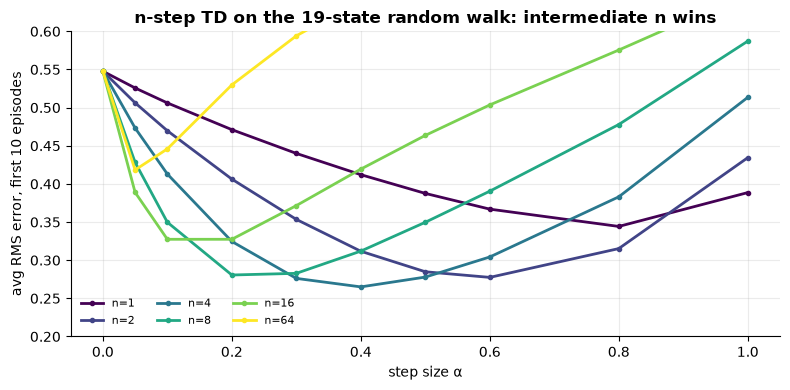

{1: 0.344, 2: 0.277, 4: 0.265, 8: 0.281, 16: 0.327, 64: 0.418} (5.5s)


In [10]:
t0 = time.perf_counter()
walk19 = RandomWalk(19, left_reward=-1.0, right_reward=1.0)
alphas = [0.0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]
ns = [1, 2, 4, 8, 16, 64]
fig, ax = plt.subplots(figsize=(8, 4))
nstep_results = {}
for j, n in enumerate(ns):
    errs = [statistics.mean(n_step_td(walk19, 10, a, n, seed=s) for s in range(30)) for a in alphas]
    nstep_results[n] = errs
    ax.plot(alphas, errs, marker="o", ms=3, lw=2, label=f"n={n}",
            color=plt.cm.viridis(j / (len(ns) - 1)))
ax.set_ylim(0.2, 0.6); ax.set_xlabel("step size α"); ax.set_ylabel("avg RMS error, first 10 episodes")
ax.set_title("n-step TD on the 19-state random walk: intermediate n wins")
ax.legend(ncol=3, fontsize=8); plt.tight_layout(); save_figure(fig, "02_n_step_td.png"); plt.show()

best = {n: min(e) for n, e in nstep_results.items()}
print({n: round(b, 3) for n, b in best.items()}, f"({time.perf_counter()-t0:.1f}s)")
assert min(best[2], best[4], best[8]) < best[1] and min(best[2], best[4], best[8]) < best[64]

## 5 · From prediction to control: learning to *act*

So far the policy was fixed. Now we want the agent to **find a good policy**. The recipe is
**Generalised Policy Iteration (GPI)**: alternate between *evaluating* the current policy and *improving* it
by acting greedily with respect to the current estimates.

Two key changes compared to prediction:

1. **Learn $Q(s,a)$, not $V(s)$.** Acting greedily w.r.t. $V$ requires the model ($\arg\max_a \sum_{s'} P(s'|s,a)[\dots]$).
   Acting greedily w.r.t. $Q$ is just $\arg\max_a Q(s,a)$ - model-free.
2. **Keep exploring.** If we always pick the current best action, we never discover that another action is
   better (notebook 01's bandit lesson). The simplest fix is **ε-greedy**: with probability ε pick a random
   action, otherwise the greedy one.

```mermaid
flowchart LR
    Q["Q(s,a) table"] -->|"ε-greedy<br/>(improve)"| P["behaviour policy π"]
    P -->|"act in env"| E["experience<br/>(s, a, r, s', a')"]
    E -->|"TD update<br/>(evaluate)"| Q
    style Q fill:#fde68a,stroke:#ea580c
    style P fill:#dbeafe,stroke:#2563eb
    style E fill:#dcfce7,stroke:#16a34a
```

### The test-bed: Cliff Walking (Sutton & Barto, Example 6.6)

A 4×12 grid. Start **S** bottom-left, goal **G** bottom-right. Every step costs −1. The bottom row between
S and G is a **cliff**: stepping into it costs −100 and sends you back to S. The shortest path runs right
along the cliff edge (13 steps, return −13). A path one row higher is safer but longer.

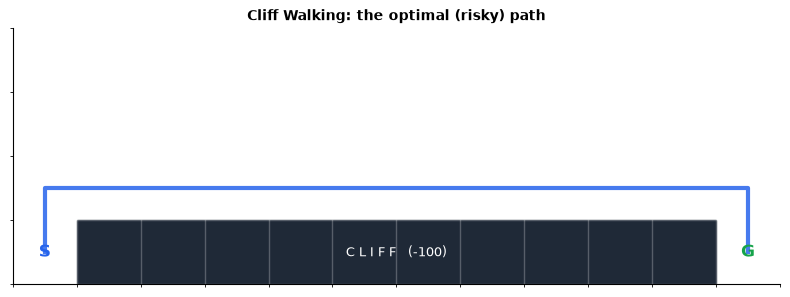

In [11]:
class CliffWalking:
    """4x12 Cliff Walking gridworld (Sutton & Barto Example 6.6), from scratch."""

    H, W = 4, 12
    START, GOAL = (3, 0), (3, 11)
    ACTIONS = [(-1, 0), (0, 1), (1, 0), (0, -1)]   # up, right, down, left
    ARROWS = ["↑", "→", "↓", "←"]

    def is_cliff(self, r, c):
        return r == 3 and 1 <= c <= 10

    def step(self, s, a):
        """Deterministic move (walls clip). Returns (next_state, reward, done)."""
        dr, dc = self.ACTIONS[a]
        r = min(max(s[0] + dr, 0), self.H - 1)
        c = min(max(s[1] + dc, 0), self.W - 1)
        if self.is_cliff(r, c):
            return self.START, -100.0, False      # fell: big penalty, teleport back to start
        return (r, c), -1.0, (r, c) == self.GOAL

    def states(self):
        return [(r, c) for r in range(self.H) for c in range(self.W)]


cliff = CliffWalking()


def draw_cliff(ax, values=None, arrows=None, path=None, title="", vmin=-100, vmax=0):
    """Draw the grid: optional heatmap of state values, greedy-action arrows and a trajectory."""
    H, W = cliff.H, cliff.W
    grid = np.full((H, W), np.nan)
    if values is not None:
        for (r, c), v in values.items():
            grid[r, c] = v
    ax.imshow(grid, cmap="YlOrRd_r", vmin=vmin, vmax=vmax)
    for c in range(1, 11):
        ax.add_patch(plt.Rectangle((c - 0.5, 2.5), 1, 1, color="#1f2937"))
    ax.text(0, 3, "S", ha="center", va="center", fontsize=12, weight="bold", color=COLORS["policy"])
    ax.text(11, 3, "G", ha="center", va="center", fontsize=12, weight="bold", color=COLORS["reward"])
    ax.text(5.5, 3, "C L I F F   (-100)", ha="center", va="center", color="white", fontsize=9)
    if arrows:
        for (r, c), a in arrows.items():
            if not cliff.is_cliff(r, c) and (r, c) != cliff.GOAL:
                ax.text(c, r, CliffWalking.ARROWS[a], ha="center", va="center", fontsize=9, color="#374151")
    if path:
        ys, xs = zip(*path)
        ax.plot(xs, ys, color=COLORS["policy"], lw=3, alpha=0.85)
    ax.set_xticks(np.arange(-0.5, W, 1), minor=True); ax.set_yticks(np.arange(-0.5, H, 1), minor=True)
    ax.grid(which="minor", color="white", lw=1); ax.grid(which="major", visible=False)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=10)


fig, ax = plt.subplots(figsize=(8, 3))
draw_cliff(ax, path=[(3, 0)] + [(2, c) for c in range(12)] + [(3, 11)], title="Cliff Walking: the optimal (risky) path")
plt.tight_layout(); save_figure(fig, "02_cliff_world.png"); plt.show()

## 6 · SARSA - on-policy TD control

### Intuition
SARSA learns *"how good is it to do $a$ in $s$, given that I will keep behaving the way I actually behave
(including my occasional random ε-moves)"*. Because it accounts for its own clumsiness, a SARSA agent near
a cliff learns to keep a safe distance.

### Math
Apply TD(0) to action values. The Bellman equation for $Q^\pi$ is
$Q^\pi(s,a) = \mathbb{E}[r + \gamma Q^\pi(s', a') ]$ with $a' \sim \pi(\cdot \mid s')$. Sampling it gives

$$\boxed{Q(s,a) \leftarrow Q(s,a) + \alpha\big[r + \gamma\,Q(s', a') - Q(s,a)\big]}$$

The update uses the quintuple $(s, a, r, s', a')$ - hence the name **S-A-R-S-A** (Rummery & Niranjan 1994;
named by Sutton 1996). It is **on-policy**: the $a'$ in the target is the action the agent will *actually* take.

### Algorithm steps

1. Initialise $Q(s,a) = 0$ for all pairs (terminal $Q = 0$).
2. Start an episode in $s$; choose $a$ ε-greedily from $Q$.
3. Take $a$; observe $r, s'$.
4. Choose $a'$ ε-greedily from $Q(s', \cdot)$ - *before* updating, because it is part of the target.
5. Update $Q(s,a)$ towards $r + \gamma Q(s',a')$ (target $= r$ if $s'$ is terminal).
6. $s \leftarrow s'$, $a \leftarrow a'$ (the action chosen in step 4 really is executed next). Repeat from 3.

In [12]:
def epsilon_greedy(Q, s, eps, rng):
    """With prob. eps a random action, else the greedy one (random tie-breaking matters at init!)."""
    if rng.random() < eps:
        return rng.randrange(4)
    best = max(Q[s])
    return rng.choice([a for a in range(4) if Q[s][a] == best])


def sarsa(env, episodes=500, alpha=0.5, eps=0.1, gamma=1.0, seed=0, snapshots=()):
    """Tabular SARSA. Returns Q, per-episode returns, and {episode: (Q copy, trajectory)} snapshots."""
    rng = random.Random(seed)
    Q = {s: [0.0] * 4 for s in env.states()}
    returns, snaps = [], {}
    for ep in range(episodes):
        s = env.START
        a = epsilon_greedy(Q, s, eps, rng)                 # step 2
        G, traj = 0.0, [s]
        while True:
            s2, r, done = env.step(s, a)                   # step 3
            a2 = epsilon_greedy(Q, s2, eps, rng)           # step 4: the action we WILL take
            target = r if done else r + gamma * Q[s2][a2]
            Q[s][a] += alpha * (target - Q[s][a])          # step 5
            s, a = s2, a2                                  # step 6
            G += r; traj.append(s)
            if done:
                break
        returns.append(G)
        if ep in snapshots:
            snaps[ep] = ({k: v.copy() for k, v in Q.items()}, traj)
    return Q, returns, snaps

## 7 · Q-learning - off-policy TD control

### Intuition
Q-learning asks a bolder question: *"how good is $a$ in $s$ if, from then on, I behave **optimally**"* - even
though, while learning, it still explores randomly. It learns about the greedy (target) policy while
following an ε-greedy (behaviour) policy. That separation is called **off-policy** learning.

### Math
Sample the **Bellman optimality** equation $Q^*(s,a) = \mathbb{E}[r + \gamma \max_{a'} Q^*(s',a')]$:

$$\boxed{Q(s,a) \leftarrow Q(s,a) + \alpha\big[r + \gamma\,\max_{a'} Q(s', a') - Q(s,a)\big]}$$

(Watkins, 1989.) The only change from SARSA is $Q(s',a') \to \max_{a'} Q(s',a')$, but the consequences are big:

* Q-learning converges to $Q^*$ (under standard conditions: every pair visited infinitely often, decaying step sizes)
  **regardless of the behaviour policy** - so it can learn from old data, other agents, or human demonstrations.
* Because it learns the value of the *greedy* policy, it ignores the cost of its own exploration. On the cliff
  this makes it walk the edge - and fall in more often *while learning*.

### Algorithm steps

1. Initialise $Q(s,a) = 0$.
2. Start an episode in $s$.
3. Choose $a$ ε-greedily (behaviour policy) and take it; observe $r, s'$.
4. Target $y = r + \gamma \max_{a'} Q(s',a')$ (or $y = r$ at terminal). *No need to know the next action.*
5. $Q(s,a) \leftarrow Q(s,a) + \alpha (y - Q(s,a))$; $s \leftarrow s'$; repeat from step 3.

In [13]:
def q_learning(env, episodes=500, alpha=0.5, eps=0.1, gamma=1.0, seed=0, snapshots=()):
    """Tabular Q-learning (Watkins 1989). Same signature/outputs as `sarsa`."""
    rng = random.Random(seed)
    Q = {s: [0.0] * 4 for s in env.states()}
    returns, snaps = [], {}
    for ep in range(episodes):
        s, G, traj = env.START, 0.0, [env.START]
        while True:
            a = epsilon_greedy(Q, s, eps, rng)             # step 3: behave epsilon-greedily
            s2, r, done = env.step(s, a)
            target = r if done else r + gamma * max(Q[s2])  # step 4: but evaluate the GREEDY policy
            Q[s][a] += alpha * (target - Q[s][a])          # step 5
            s = s2; G += r; traj.append(s)
            if done:
                break
        returns.append(G)
        if ep in snapshots:
            snaps[ep] = ({k: v.copy() for k, v in Q.items()}, traj)
    return Q, returns, snaps


def greedy_path(Q, env, max_steps=60):
    """Follow argmax_a Q from the start (no exploration)."""
    s, path = env.START, [env.START]
    for _ in range(max_steps):
        a = max(range(4), key=lambda k: Q[s][k])
        s, _, done = env.step(s, a)
        path.append(s)
        if done:
            break
    return path

### Experiment: SARSA vs Q-learning on the cliff

We train each algorithm for 500 episodes with ε = 0.1, α = 0.5, averaged over 20 seeds.

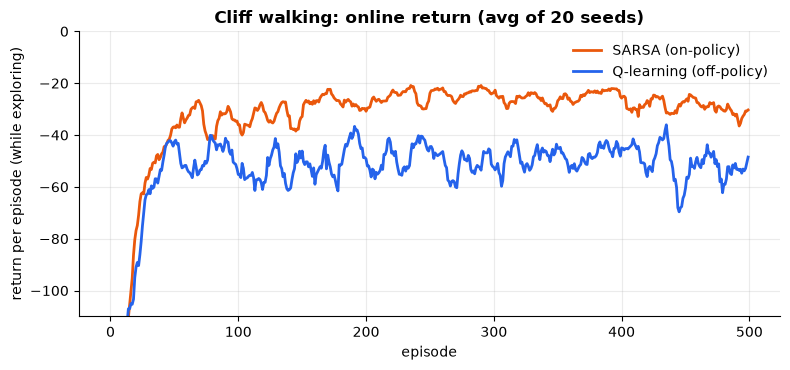

mean online return, last 100 episodes: SARSA -29.0, Q-learning -51.0
Q-learning greedy path lengths: [13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13]
(1.4s)


In [14]:
t0 = time.perf_counter()
SEEDS = 20
avg_ret = {"SARSA": np.zeros(500), "Q-learning": np.zeros(500)}
qlearn_paths, sarsa_paths = [], []
for seed in range(SEEDS):
    Qs, rs, _ = sarsa(cliff, seed=seed)
    Qq, rq, _ = q_learning(cliff, seed=seed)
    avg_ret["SARSA"] += np.array(rs) / SEEDS
    avg_ret["Q-learning"] += np.array(rq) / SEEDS
    sarsa_paths.append(greedy_path(Qs, cliff)); qlearn_paths.append(greedy_path(Qq, cliff))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(smooth(avg_ret["SARSA"], 10), color=COLORS["value"], lw=2, label="SARSA (on-policy)")
ax.plot(smooth(avg_ret["Q-learning"], 10), color=COLORS["policy"], lw=2, label="Q-learning (off-policy)")
ax.set_ylim(-110, 0); ax.set_xlabel("episode"); ax.set_ylabel("return per episode (while exploring)")
ax.set_title("Cliff walking: online return (avg of 20 seeds)"); ax.legend()
plt.tight_layout(); save_figure(fig, "02_sarsa_vs_q_returns.png"); plt.show()

q_lens = [len(p) - 1 for p in qlearn_paths]
sarsa_last = avg_ret["SARSA"][-100:].mean(); q_last = avg_ret["Q-learning"][-100:].mean()
print(f"mean online return, last 100 episodes: SARSA {sarsa_last:.1f}, Q-learning {q_last:.1f}")
print("Q-learning greedy path lengths:", q_lens)
print(f"({time.perf_counter()-t0:.1f}s)")
assert sarsa_last > q_last, "SARSA should earn more reward online (it avoids the cliff edge)"
assert all(L == 13 for L in q_lens), "Q-learning's greedy policy should be the optimal 13-step path"

What the numbers say:

* **Q-learning's greedy policy is optimal** (13 steps along the edge), but its *online* return is worse: with
  ε = 0.1 a random step off the edge sends it into the cliff now and then.
* **SARSA's online return is better** because it learned the value of its *actual* (exploring) behaviour, which
  favours a path further from the cliff. If ε were decayed to 0, both would converge to the optimal path.

This is a recurring theme in RL for LLMs: *what policy are your values/advantages describing?* PPO's critic
estimates the value of the *current sampling policy* (on-policy, like SARSA); methods that learn from logged
or stale data must correct for the mismatch (off-policy, like Q-learning) - see notebook 13.

### Animation: values propagating, paths diverging

Each frame is a snapshot during training (seed 0). The colour is $\max_a Q(s,a)$ (bright = close to the goal,
dark = far / dangerous), the small arrows are the greedy actions, and the blue line is **the trajectory the
agent actually walked in that episode**. Watch the value "wave" spread backwards from G, one TD update at a
time, and the two algorithms settle on different routes.


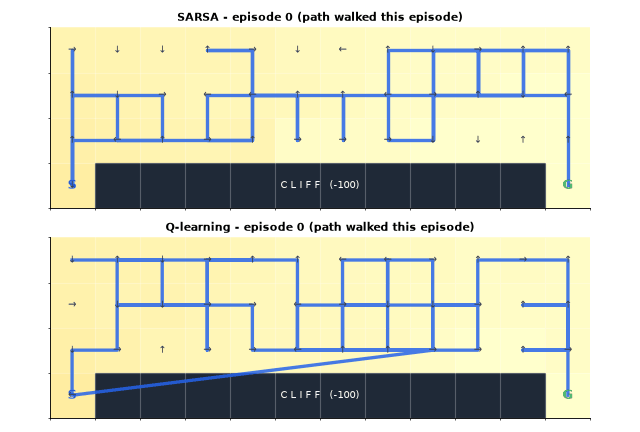

PosixPath('/Users/naveenkumarbasaanitha/Music/HaloDiffusionLLM/assets/rl/course/02_cliff_sarsa_vs_q.gif')

In [15]:
SNAP = sorted(set([0, 1, 2, 3, 5, 8, 10, 13, 16, 20, 25, 30, 35, 40, 50, 60, 70, 80, 100, 120, 150,
                   180, 220, 260, 300, 350, 400, 450, 499]))
_, _, sarsa_snaps = sarsa(cliff, seed=0, snapshots=SNAP)
_, _, q_snaps = q_learning(cliff, seed=0, snapshots=SNAP)


def draw_cliff_training(fig, i):
    fig.clf()
    ep = SNAP[i]
    for row, (name, snaps) in enumerate([("SARSA", sarsa_snaps), ("Q-learning", q_snaps)]):
        ax = fig.add_subplot(2, 1, row + 1)
        Q, traj = snaps[ep]
        values = {s: max(q) for s, q in Q.items() if not cliff.is_cliff(*s)}
        arrows = {s: max(range(4), key=lambda k: q[k]) for s, q in Q.items()}
        draw_cliff(ax, values, arrows, traj[-80:], title=f"{name} - episode {ep} (path walked this episode)",
                   vmin=-30, vmax=0)
    fig.tight_layout()


Animator(draw_cliff_training, n_frames=len(SNAP), figsize=(8, 5.4), fps=3).save("02_cliff_sarsa_vs_q.gif")

## 8 · Double Q-learning - fixing the maximization bias

### Intuition
Ten students each guess the weight of a cow; all guesses are noisy but unbiased. If you report **the
largest guess**, you will systematically overestimate the weight. Q-learning's target $\max_{a'} Q(s',a')$ does
exactly this: it takes a max over *noisy estimates*, and $\mathbb{E}[\max_i X_i] \ge \max_i \mathbb{E}[X_i]$
(Jensen's inequality, since max is convex). This is the **maximization bias**.

### Math
Double Q-learning (van Hasselt, 2010) keeps **two independent tables** $Q_A, Q_B$. One *chooses* the action,
the other *evaluates* it:

$$Q_A(s,a) \leftarrow Q_A(s,a) + \alpha\Big[r + \gamma\, Q_B\big(s', \arg\max_{a'} Q_A(s',a')\big) - Q_A(s,a)\Big]$$

and symmetrically for $Q_B$ (each step, flip a coin to decide which table to update). Because $Q_B$'s noise is
independent of the noise that made $Q_A$ pick $a'$, the evaluation is no longer biased upwards. The same trick,
with the target network playing the role of $Q_B$, is **Double DQN** in notebook 03.

### Algorithm steps
1. Initialise $Q_A, Q_B$. Behave ε-greedily w.r.t. $Q_A + Q_B$.
2. After each transition flip a coin. If heads: $a^* = \arg\max_{a'} Q_A(s',a')$, target $= r + \gamma Q_B(s', a^*)$, update $Q_A$.
   If tails: swap the roles of A and B.

### Test-bed (Sutton & Barto, Example 6.7)
From state **A**: action *right* ends the episode with reward 0; action *left* goes to **B** (reward 0). From B
there are 10 actions, each ending the episode with reward $\sim \mathcal{N}(-0.1, 1)$. *Left is a bad idea on
average* (−0.1), but some of B's noisy estimates will look positive, and Q-learning's max will believe them.
With ε = 0.1 the optimal behaviour picks *left* only 5% of the time (the random-action share).

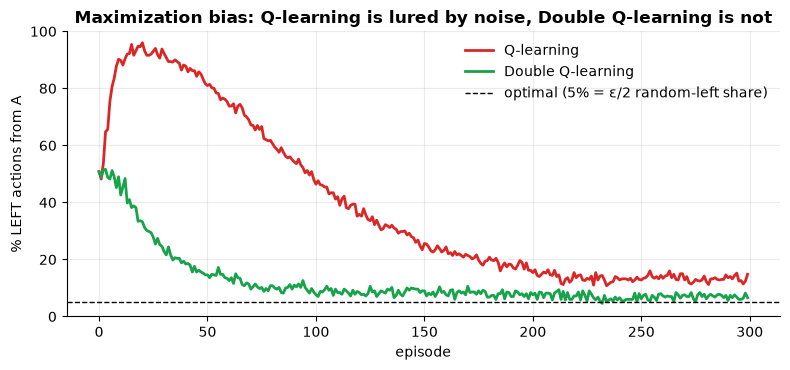

peak % left - Q-learning: 96%, Double Q: 52%; mean over first 100 episodes: 75% vs 21%  (0.9s)


In [16]:
def maximization_bias(double, episodes=300, runs=500, alpha=0.1, eps=0.1, n_b_actions=10):
    """Fraction of runs choosing LEFT in state A at each episode. Pure-python, two-state MDP."""
    left_counts = np.zeros(episodes)
    for run in range(runs):
        rng = random.Random(run)
        QA = {"A": [0.0, 0.0], "B": [0.0] * n_b_actions}     # A: 0 = left, 1 = right
        QB = {"A": [0.0, 0.0], "B": [0.0] * n_b_actions}

        def act(s):
            q = [x + (y if double else 0.0) for x, y in zip(QA[s], QB[s])]
            if rng.random() < eps:
                return rng.randrange(len(q))
            m = max(q)
            return rng.choice([i for i, v in enumerate(q) if v == m])

        def update(s, a, r, s2):
            if not double:                                    # plain Q-learning on QA
                target = r + (max(QA[s2]) if s2 else 0.0)
                QA[s][a] += alpha * (target - QA[s][a]); return
            X, Y = (QA, QB) if rng.random() < 0.5 else (QB, QA)
            if s2:
                a_star = max(range(len(X[s2])), key=lambda k: X[s2][k])  # X chooses...
                target = r + Y[s2][a_star]                               # ...Y evaluates
            else:
                target = r
            X[s][a] += alpha * (target - X[s][a])

        for ep in range(episodes):
            a = act("A")
            left_counts[ep] += (a == 0) / runs
            if a == 1:
                update("A", 1, 0.0, None)
                continue
            update("A", 0, 0.0, "B")
            b = act("B")
            update("B", b, rng.gauss(-0.1, 1.0), None)
    return left_counts


t0 = time.perf_counter()
left_q = maximization_bias(double=False)
left_dq = maximization_bias(double=True)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(left_q * 100, color=COLORS["penalty"], lw=2, label="Q-learning")
ax.plot(left_dq * 100, color=COLORS["reward"], lw=2, label="Double Q-learning")
ax.axhline(5, color="k", ls="--", lw=1, label="optimal (5% = ε/2 random-left share)")
ax.set_xlabel("episode"); ax.set_ylabel("% LEFT actions from A"); ax.set_ylim(0, 100)
ax.set_title("Maximization bias: Q-learning is lured by noise, Double Q-learning is not"); ax.legend()
plt.tight_layout(); save_figure(fig, "02_maximization_bias.png"); plt.show()
print(f"peak % left - Q-learning: {left_q.max()*100:.0f}%, Double Q: {left_dq.max()*100:.0f}%;"
      f" mean over first 100 episodes: {left_q[:100].mean()*100:.0f}% vs {left_dq[:100].mean()*100:.0f}%"
      f"  ({time.perf_counter()-t0:.1f}s)")
assert left_q[:100].mean() > left_dq[:100].mean() + 0.1

## 9 · Common pitfalls

| Pitfall | Symptom | Fix |
|---|---|---|
| Forgetting $V(\text{terminal}) = 0$ / bootstrapping past `done` | values drift or explode | `target = r if done else r + γ·max Q(s')` |
| Deterministic tie-breaking at init (`argmax` of all zeros) | agent always picks action 0, never explores parts of the space | break ties randomly |
| No exploration (ε = 0 from the start) | stuck on the first path that reached the goal | ε-greedy, optimistic init, UCB (notebook 01) |
| Step size too large for MC | estimates jump around forever | smaller α, or decay α |
| Confusing online return with greedy-policy quality | "Q-learning is worse than SARSA!" on the cliff | evaluate the greedy policy separately |
| Taking max over noisy estimates | systematic over-estimation (Section 8) | Double Q-learning / Double DQN |
| Using SARSA with stale data from another policy | biased values | on-policy methods need fresh data; otherwise importance-weight |

## 10 · How this connects to LLM and VLM training

```mermaid
flowchart TB
    TD["TD error<br/>δ = r + γV(s') − V(s)"] --> GAE["GAE(λ) advantages<br/>(notebook 05)"]
    GAE --> PPO["PPO critic / value head in RLHF<br/>(notebooks 06–07)"]
    QL["Q-learning<br/>max over next action"] --> DQN["DQN (notebook 03)"]
    QL --> ILQL["Offline token-level Q-learning<br/>for LMs (ILQL, Snell et al. 2022)"]
    QL --> SOFTQ["Soft Q-learning view:<br/>LM logits ≈ Q-values<br/>(DPO 'From r to Q*', Rafailov et al. 2024)"]
    NSTEP["n-step / λ-returns"] --> GAE
    DQL["Double Q-learning"] --> DDQN["Double DQN (notebook 03)"]
```

* **State = prompt + tokens so far, action = next token.** Text generation is an MDP with a huge action space
  (the vocabulary) and usually a single reward at the end. Tabular methods are hopeless there - one entry per
  possible prefix! - which is why we need function approximation (notebook 03) and policy gradients (04).
* **The TD error survives.** In PPO-based RLHF a *value head* $V(s_t)$ predicts the future reward from every
  token position; per-token TD errors $\delta_t = r_t + \gamma V(s_{t+1}) - V(s_t)$ are combined into GAE
  advantages - the n-step/λ dial from Section 4.
* **Bias vs variance again.** Critic-free LLM methods such as GRPO and RLOO (notebook 09) are essentially
  **Monte Carlo**: they score whole sampled responses and use group averages as baselines. They accept the
  variance of MC to avoid training a second large network as a critic.
* **Off-policy vs on-policy matters.** Rollouts produced by an inference engine or by an older checkpoint are
  slightly off-policy. Large-scale systems correct with importance weights (notebook 13) - the same issue that
  separates SARSA from Q-learning.
* **Q-learning for language exists.** ILQL learns token-level Q-values from offline data; Rafailov et al. (2024)
  show a DPO-trained LM's logits can be interpreted as an optimal soft Q-function over tokens.

## 11 · Cheat sheet

| Algorithm | Learns | Target | On/off-policy | Bias | Variance | Key idea |
|---|---|---|---|---|---|---|
| MC prediction | $V^\pi$ | $G_t$ | on | none | high | average complete returns |
| TD(0) | $V^\pi$ | $r + \gamma V(s')$ | on | from $V$ | low | bootstrap after each step |
| n-step TD | $V^\pi$ | $n$ rewards + $\gamma^n V(s_{t+n})$ | on | tunable | tunable | dial between TD and MC |
| SARSA | $Q^\pi$ | $r + \gamma Q(s',a')$ | **on** | from $Q$ | low | value of what you actually do |
| Q-learning | $Q^*$ | $r + \gamma \max_{a'} Q(s',a')$ | **off** | + max bias | low | value of the greedy policy |
| Double Q-learning | $Q^*$ | $r + \gamma Q_B(s', \arg\max Q_A)$ | off | reduced | low | decouple choose vs evaluate |

**Take-aways:** (1) every method is "estimate += α · (target − estimate)", only the target changes;
(2) bootstrapping trades bias for variance; (3) on-policy methods value your exploring behaviour, off-policy
methods value the greedy policy; (4) max over noisy estimates over-estimates. Next: notebook 03 replaces the
table with a neural network - DQN.

In [17]:
print(f"notebook ran in {time.perf_counter() - NOTEBOOK_START:.0f}s")

notebook ran in 28s
